# Day 4 · Demo 2: pooling and shrinkage

Bayesian statistics for PhD researchers, Aalborg University 2026. This notebook reproduces the figures of the **Day 4 afternoon slides**. Each section names its slide. Run it with the **R (bayes)** kernel from the `demos/` folder; each model compiles once (about a minute each).

The data are the slides' **illustrative** time-game data: 12 people, 2 to 10 attempts each at waiting 10 seconds.

**Try it** (section 6): change `ATTEMPTS` to see how shrinkage and the funnel depend on the number of attempts per person.

In [1]:
options(tidyverse.quiet = TRUE)
library(tidyverse)   # dplyr for summaries, ggplot2 for figures
library(cmdstanr)    # Stan from R
set.seed(2026)
options(width = 95, repr.plot.width = 8, repr.plot.height = 5, repr.plot.bg = "white")

d <- read_csv("data/slides-class-timing.csv", show_col_types = FALSE)   # person, attempt, seconds
d |> count(person)

This is cmdstanr version 0.9.0

- CmdStanR documentation and vignettes: mc-stan.org/cmdstanr

- CmdStan path: /opt/homebrew/Caskroom/miniconda/base/envs/bayes/bin/cmdstan

- CmdStan version: 2.40.0



person,n
<chr>,<int>
P01,10
P02,10
P03,10
P04,10
P05,10
P06,10
P07,8
P08,6
P09,5


## 1. The whole class

*Slide "Now the whole class".* Each dot is one attempt; the bar is the person's own average.

person,n,own_mean
<chr>,<int>,<dbl>
P01,10,9.8100
P02,10,9.4100
P03,10,10.2800
P04,10,9.7100
P05,10,10.9100
P06,10,10.1000
P07,8,8.6125
P08,6,9.0000
P09,5,10.6000


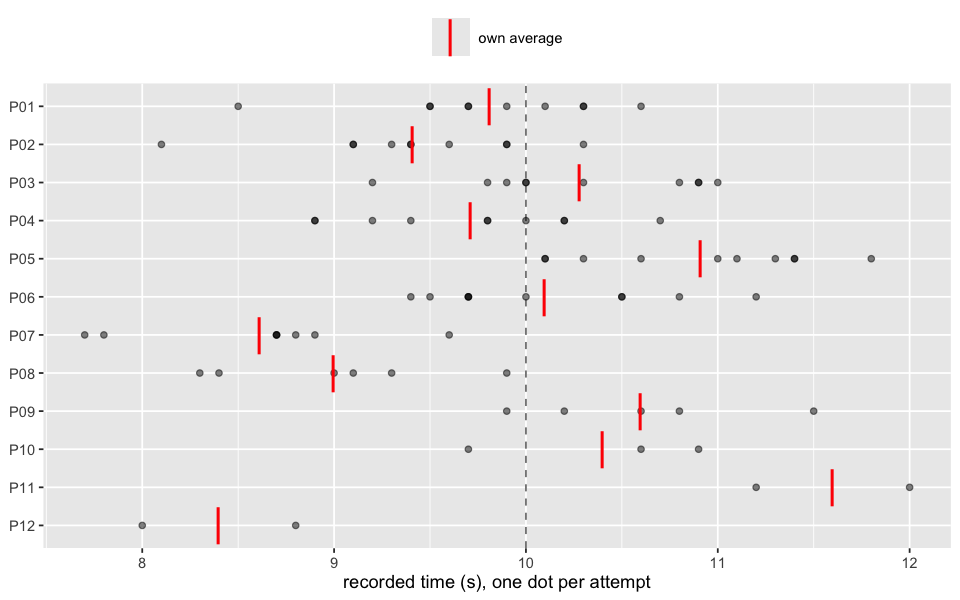

In [2]:
own <- d |> group_by(person) |> summarise(n = n(), own_mean = mean(seconds))
own

ggplot(d, aes(x = seconds, y = person)) +
  geom_vline(xintercept = 10, linetype = "dashed", colour = "grey50") +
  geom_point(alpha = 0.5) +
  geom_point(data = own, aes(x = own_mean, colour = "own average"), shape = 124, size = 8) +
  scale_colour_manual(values = c("own average" = "red"), name = NULL) +
  theme(legend.position = "top") +
  scale_y_discrete(limits = rev) + labs(x = "recorded time (s), one dot per attempt", y = NULL)

## 2. Three models

*Slides "Three ways to use the class" and "The hierarchical model".* Stan needs each person as a number 1, …, J.

In [3]:
people <- sort(unique(d$person))
d <- d |> mutate(id = match(person, people))
stan_data <- list(N = nrow(d), J = length(people), person = d$id, y = d$seconds)

fit_complete <- cmdstan_model("models/complete_pooling.stan")$sample(data = stan_data, chains = 4, seed = 2026, refresh = 0)
fit_nopool   <- cmdstan_model("models/no_pooling.stan")$sample(data = stan_data, chains = 4, seed = 2026, refresh = 0)
mod_hier     <- cmdstan_model("models/hierarchical.stan")
fit_partial  <- mod_hier$sample(data = stan_data, chains = 4, seed = 2026, refresh = 0)

tibble(model       = c("complete", "no pooling", "partial"),
       max_rhat    = c(max(fit_complete$summary()$rhat, na.rm = TRUE), max(fit_nopool$summary()$rhat, na.rm = TRUE), max(fit_partial$summary()$rhat, na.rm = TRUE)),
       divergences = c(sum(fit_complete$diagnostic_summary()$num_divergent), sum(fit_nopool$diagnostic_summary()$num_divergent), sum(fit_partial$diagnostic_summary()$num_divergent)))

fit_partial$summary(c("mu", "tau", "sigma"), "mean", ~quantile(.x, c(0.05, 0.95)))

Running MCMC with 4 sequential chains...

Chain 1 finished in 0.0 seconds.
Chain 2 finished in 0.0 seconds.
Chain 3 finished in 0.0 seconds.
Chain 4 finished in 0.0 seconds.

All 4 chains finished successfully.
Mean chain execution time: 0.0 seconds.
Total execution time: 0.6 seconds.



Running MCMC with 4 sequential chains...

Chain 1 finished in 0.0 seconds.
Chain 2 finished in 0.0 seconds.
Chain 3 finished in 0.0 seconds.
Chain 4 finished in 0.0 seconds.

All 4 chains finished successfully.
Mean chain execution time: 0.0 seconds.
Total execution time: 0.5 seconds.



Running MCMC with 4 sequential chains...

Chain 1 finished in 0.1 seconds.
Chain 2 finished in 0.1 seconds.
Chain 3 finished in 0.1 seconds.
Chain 4 finished in 0.1 seconds.

All 4 chains finished successfully.
Mean chain execution time: 0.1 seconds.
Total execution time: 0.6 seconds.



model,max_rhat,divergences
<chr>,<dbl>,<dbl>
complete,1.001191,0
no pooling,1.003429,0
partial,1.005996,0


variable,mean,5%,95%
<chr>,<dbl>,<dbl>,<dbl>
mu,9.8918739,9.3993950,10.3679390
tau,0.9062593,0.5998623,1.3019446
sigma,0.6118137,0.5357253,0.7024125


## 3. Shrinkage

*Slides "Where the weight w comes from", "Shrinkage: a compromise, again" and "Shrinkage in the class".* The formula wⱼ = (nⱼ/σ²) / (nⱼ/σ² + 1/τ²), with the posterior means of σ, τ and μ plugged in, gives almost the same estimates as the full fit.

person,n,own_mean,no_pool,partial,w,formula
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
P01,10,9.8100,9.806893,9.814298,0.9564109,9.813569
P02,10,9.4100,9.412211,9.431701,0.9564109,9.431004
P03,10,10.2800,10.277829,10.261695,0.9564109,10.263082
P04,10,9.7100,9.716558,9.716520,0.9564109,9.717928
P05,10,10.9100,10.900301,10.859238,0.9564109,10.865621
P06,10,10.1000,10.099112,10.085982,0.9564109,10.090928
P07,8,8.6125,8.628180,8.689424,0.9461010,8.681457
P08,6,9.0000,9.012812,9.063867,0.9294030,9.062964
P09,5,10.6000,10.589726,10.536113,0.9164631,10.540845


mu     sigma       tau 
9.8918739 0.6118137 0.9062593

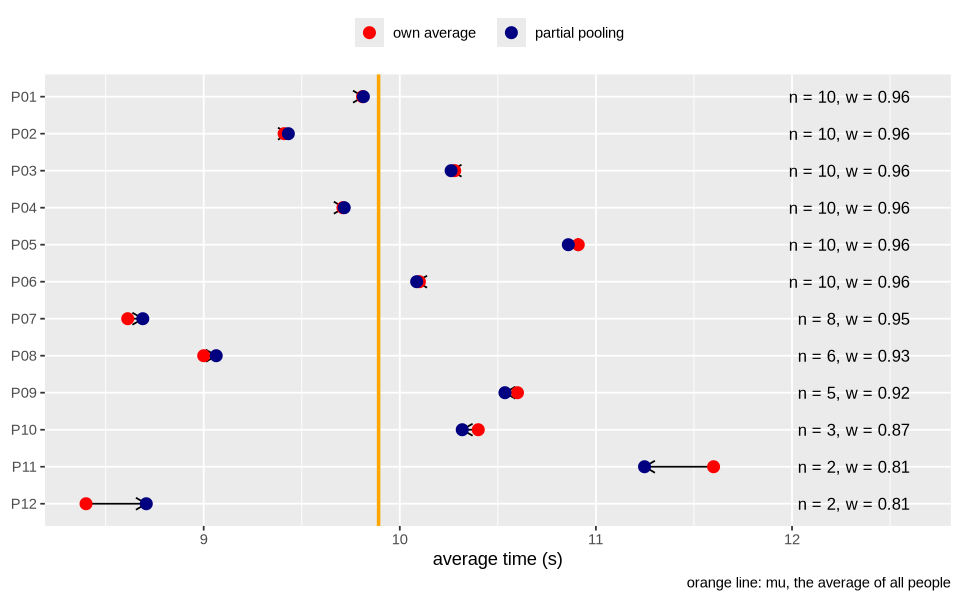

In [4]:
mu_hat    <- fit_partial$summary("mu")$mean
sigma_hat <- fit_partial$summary("sigma")$mean
tau_hat   <- fit_partial$summary("tau")$mean

own <- own |> mutate(no_pool = fit_nopool$summary("theta")$mean,
                     partial = fit_partial$summary("theta")$mean,
                     w       = (n / sigma_hat^2) / (n / sigma_hat^2 + 1 / tau_hat^2),
                     formula = w * own_mean + (1 - w) * mu_hat)
own
c(mu = mu_hat, sigma = sigma_hat, tau = tau_hat)

ggplot(own, aes(y = person)) +
  geom_vline(xintercept = mu_hat, colour = "orange", linewidth = 1) +
  geom_segment(aes(x = own_mean, xend = partial, yend = person), arrow = arrow(length = unit(0.1, "inches"))) +
  geom_point(aes(x = own_mean, colour = "own average"), size = 3) +
  geom_point(aes(x = partial, colour = "partial pooling"), size = 3) +
  geom_text(aes(x = 12.6, label = paste0("n = ", n, ", w = ", round(w, 2))), hjust = 1, size = 3.5) +
  scale_y_discrete(limits = rev) +
  scale_colour_manual(values = c("own average" = "red", "partial pooling" = "navy"), name = NULL) +
  theme(legend.position = "top") +
  labs(x = "average time (s)", y = NULL, caption = "orange line: mu, the average of all people")

## 4. Three models side by side

*Slide "Three models side by side".* Posterior means and 90% intervals of each person's average.

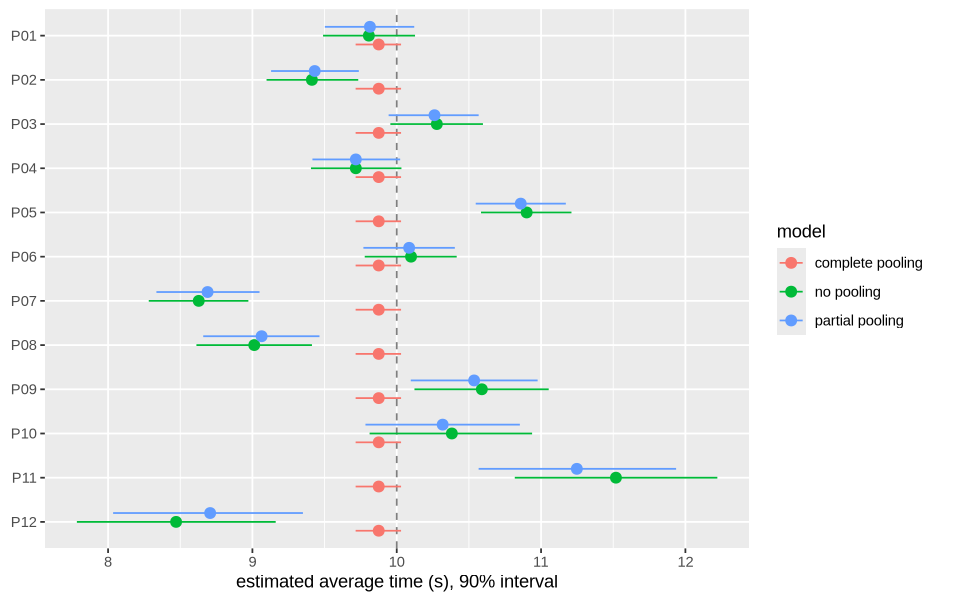

In [5]:
mu_complete <- fit_complete$draws(format = "df")$mu
estimates <- bind_rows(
  tibble(person = people, model = "complete pooling", est = mean(mu_complete),
         lo = quantile(mu_complete, 0.05), hi = quantile(mu_complete, 0.95)),
  fit_nopool$summary("theta", "mean", ~quantile(.x, c(0.05, 0.95))) |>
    transmute(person = people, model = "no pooling", est = mean, lo = `5%`, hi = `95%`),
  fit_partial$summary("theta", "mean", ~quantile(.x, c(0.05, 0.95))) |>
    transmute(person = people, model = "partial pooling", est = mean, lo = `5%`, hi = `95%`))

ggplot(estimates, aes(x = est, y = person, colour = model)) +
  geom_vline(xintercept = 10, linetype = "dashed", colour = "grey50") +
  geom_pointrange(aes(xmin = lo, xmax = hi), position = position_dodge(width = 0.6)) +
  scale_y_discrete(limits = rev) + labs(x = "estimated average time (s), 90% interval", y = NULL)

## 5. Predicting a known person and a new person

*Slide "Predicting: a person we know, or a new person".* `hierarchical.stan` generates `y_next[j]` (the next attempt of person j) and `y_new_person` (θ_new ~ Normal(μ, τ), then ỹ ~ Normal(θ_new, σ)).

who,mean,q5,q95,width
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
P04 (10 attempts),9.711411,8.655374,10.73005,2.074674
P11 (2 attempts),11.259420,10.041074,12.46154,2.420466
a new person,9.894768,7.947945,11.76821,3.820264


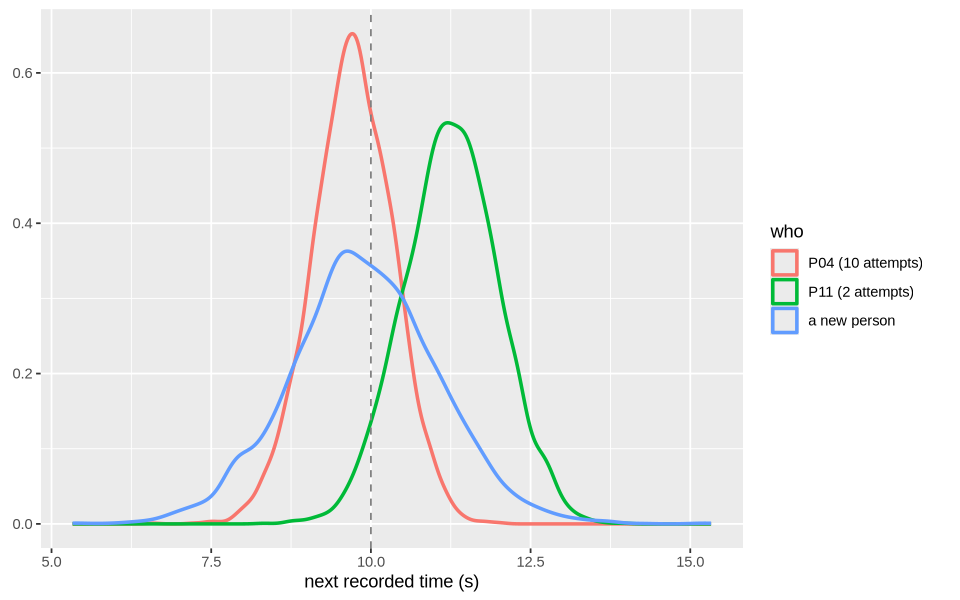

In [6]:
draws_p <- fit_partial$draws(format = "df")
pred <- bind_rows(tibble(seconds = draws_p$`y_next[4]`,  who = "P04 (10 attempts)"),
                  tibble(seconds = draws_p$`y_next[11]`, who = "P11 (2 attempts)"),
                  tibble(seconds = draws_p$y_new_person, who = "a new person"))
pred |> group_by(who) |>
  summarise(mean = mean(seconds), q5 = quantile(seconds, 0.05), q95 = quantile(seconds, 0.95)) |>
  mutate(width = q95 - q5)

ggplot(pred, aes(x = seconds, colour = who)) + geom_density(linewidth = 1) +
  geom_vline(xintercept = 10, linetype = "dashed", colour = "grey50") + labs(x = "next recorded time (s)", y = NULL)

## 6. Try it: fewer attempts, more shrinkage — and the funnel

*Slides "A warning sign: the funnel" and "Non-centred: same model, easier shape".* Keep only the first `ATTEMPTS` attempts of every person and fit both versions of the hierarchical model. With 2 attempts the centred version produces divergences; the non-centred one does not. Try `ATTEMPTS <- 3` or `5`.

In [7]:
ATTEMPTS <- 2
d_few <- d |> filter(attempt <= ATTEMPTS)
data_few <- list(N = nrow(d_few), J = length(people), person = d_few$id, y = d_few$seconds)

fit_centred    <- cmdstan_model("models/hierarchical_centered.stan")$sample(data = data_few, chains = 4, seed = 2026, refresh = 0)
fit_noncentred <- mod_hier$sample(data = data_few, chains = 4, seed = 2026, refresh = 0)

c(divergences_centred     = sum(fit_centred$diagnostic_summary()$num_divergent),
  divergences_non_centred = sum(fit_noncentred$diagnostic_summary()$num_divergent))

Running MCMC with 4 sequential chains...

Chain 1 finished in 0.0 seconds.
Chain 2 finished in 0.0 seconds.


Chain 3 Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:



Chain 3 Exception: normal_lpdf: Scale parameter is 0, but must be positive! (in '/tmp/RtmpSngmRV/model-17549fe3919.stan', line 18, column 2 to column 26)



Chain 3 If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,



Chain 3 but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.



Chain 3 



... (7 outputs left out)

Chain 4 



Chain 4 finished in 0.1 seconds.

All 4 chains finished successfully.
Mean chain execution time: 0.1 seconds.
Total execution time: 0.5 seconds.



See https://mc-stan.org/misc/warnings for details.




divergences_centred divergences_non_centred 
                     27                       0

The funnel: in the centred fit, plot person 1's deviation from μ against log τ, with divergent draws in red. They sit in the narrow neck, where τ is small.

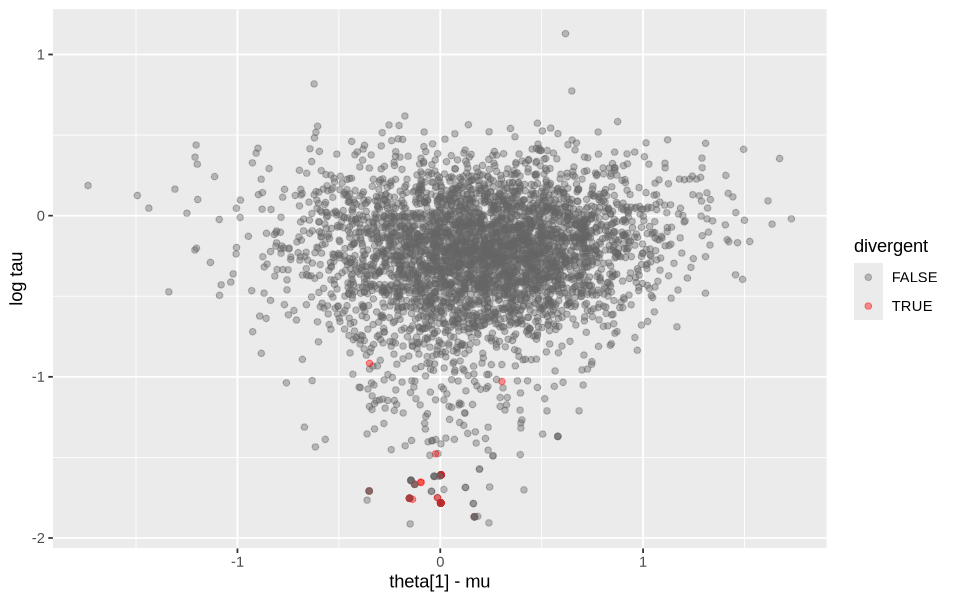

In [8]:
funnel <- fit_centred$draws(format = "df") |>
  mutate(divergent = fit_centred$sampler_diagnostics(format = "df")$divergent__ == 1)
ggplot(funnel, aes(x = `theta[1]` - mu, y = log(tau), colour = divergent)) +
  geom_point(alpha = 0.4) + scale_colour_manual(values = c("grey40", "red")) +
  labs(x = "theta[1] - mu", y = "log tau")

Shrinkage with only `ATTEMPTS` attempts per person: the arrows are longer, because nⱼ/σ² is smaller and so wⱼ is smaller.

mean_move_all_attempts mean_move_few_attempts 
            0.08844516             0.19089591

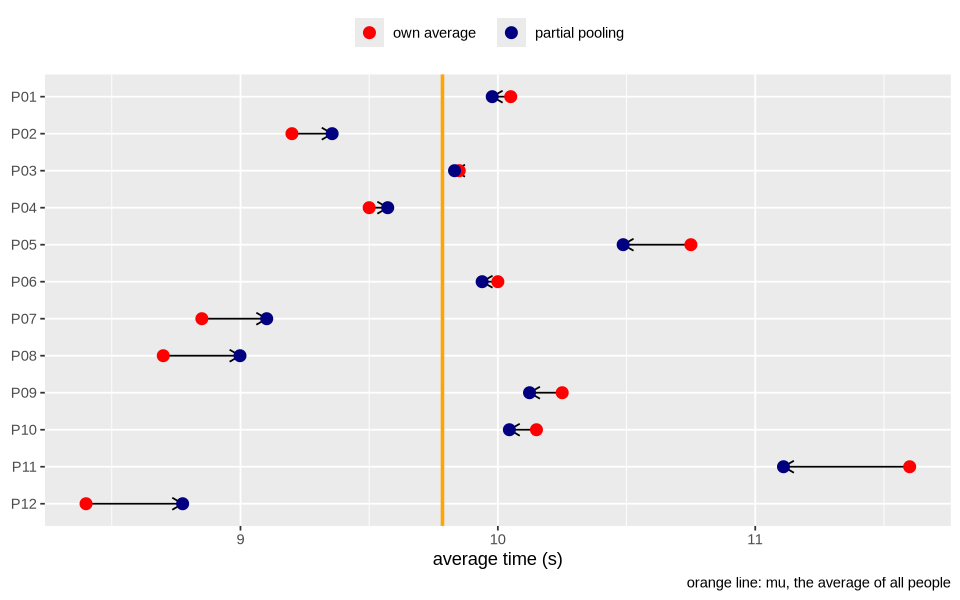

In [9]:
own_few <- d_few |> group_by(person) |> summarise(n = n(), own_mean = mean(seconds)) |>
  mutate(partial = fit_noncentred$summary("theta")$mean)
mu_few <- fit_noncentred$summary("mu")$mean
ggplot(own_few, aes(y = person)) +
  geom_vline(xintercept = mu_few, colour = "orange", linewidth = 1) +
  geom_segment(aes(x = own_mean, xend = partial, yend = person), arrow = arrow(length = unit(0.1, "inches"))) +
  geom_point(aes(x = own_mean, colour = "own average"), size = 3) +
  geom_point(aes(x = partial, colour = "partial pooling"), size = 3) +
  scale_y_discrete(limits = rev) +
  scale_colour_manual(values = c("own average" = "red", "partial pooling" = "navy"), name = NULL) +
  theme(legend.position = "top") +
  labs(x = "average time (s)", y = NULL, caption = "orange line: mu, the average of all people")
c(mean_move_all_attempts = mean(abs(own$partial - own$own_mean)),
  mean_move_few_attempts = mean(abs(own_few$partial - own_few$own_mean)))